# Interpreting the best boosting model (issue #16)

Which sensors matter, and how? Best single model so far (#13): **CatBoost** with the parameters tuned in `boosting_catboost.ipynb` (nested-CV AUC 0.703, effectively tied with LightGBM 0.7025 and XGBoost 0.7018; see `results/model_results.csv`).

Protocol (`src/common.py`, #8): the test set is not touched. Models are fit on the official **train** split and explained on the official **val** split (1,954 rows). Features are the 6 raw sensors (the engineered columns did not help in #14). Figures go to `reports/figures/`.

Caution: with ROC AUC of only about 0.70 the models have learned a weak signal, so importances are small and should be read as "what the model leans on", not as causes.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score

from src.common import load_train_val, RANDOM_STATE, ROOT
warnings.filterwarnings('ignore')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
P = lambda n: json.loads((ROOT / 'results' / f'best_params_{n}.json').read_text())

X_tr, y_tr, X_va, y_va = load_train_val()
models = {
  'CatBoost':  CatBoostClassifier(**P('catboost'), random_seed=RANDOM_STATE, thread_count=4, verbose=0, allow_writing_files=False),
  'XGBoost':   XGBClassifier(**P('xgboost'), random_state=RANDOM_STATE, n_jobs=4, tree_method='hist'),
  'LightGBM':  LGBMClassifier(**P('lightgbm'), subsample_freq=1, random_state=RANDOM_STATE, n_jobs=4, verbose=-1),
}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    print(f'{name:9s} validation AUC {roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]):.4f}')

CatBoost  validation AUC 0.7093
XGBoost   validation AUC 0.7068
LightGBM  validation AUC 0.7083


## 1. Permutation importance (validation data)

Drop in ROC AUC when one sensor's values are shuffled (30 repeats). Error bars are the std over repeats.

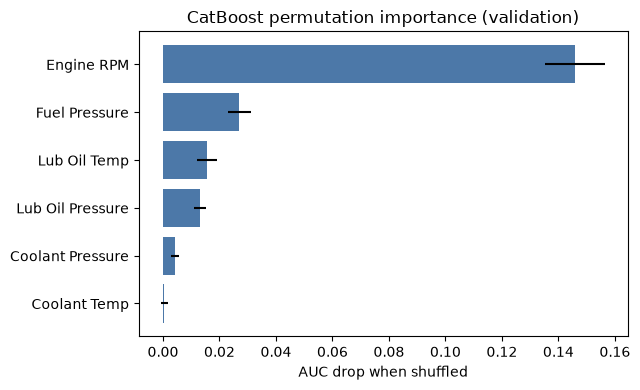

,mean,std
Engine RPM,0.1459,0.0108
Fuel Pressure,0.0270,0.0040
Lub Oil Temp,0.0156,0.0034
Lub Oil Pressure,0.0132,0.0022
Coolant Pressure,0.0041,0.0014
Coolant Temp,0.0005,0.0012


In [2]:
perm = {}
for name, m in models.items():
    r = permutation_importance(m, X_va, y_va, scoring='roc_auc', n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
    perm[name] = pd.DataFrame({'mean': r.importances_mean, 'std': r.importances_std}, index=X_va.columns)
cb = perm['CatBoost'].sort_values('mean')
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(cb.index, cb['mean'], xerr=cb['std'], color='#4c78a8')
ax.set_xlabel('AUC drop when shuffled'); ax.set_title('CatBoost permutation importance (validation)')
plt.tight_layout(); plt.savefig(FIG / 'interp_permutation_catboost.png', dpi=130); plt.show()
perm['CatBoost'].sort_values('mean', ascending=False).round(4)

## 2. SHAP (TreeExplainer) for CatBoost

SHAP values say how much each sensor pushed each validation prediction toward "Needs Maintenance" (log-odds). Summary: one dot per engine; colour = sensor value.

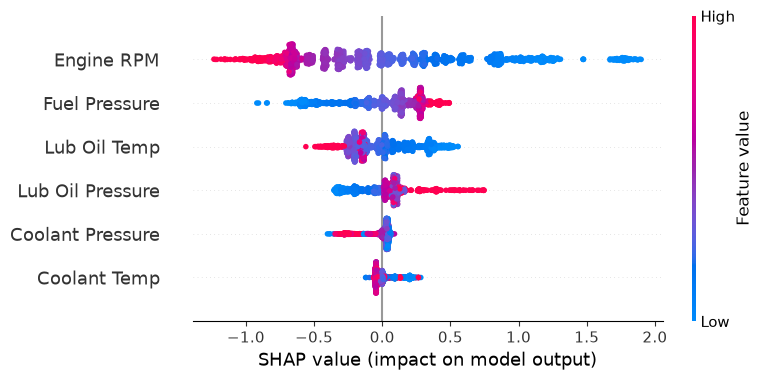

Engine RPM          0.5643
Fuel Pressure       0.2472
Lub Oil Temp        0.1911
Lub Oil Pressure    0.1343
Coolant Pressure    0.0530
Coolant Temp        0.0477
dtype: float64

In [3]:
expl = shap.TreeExplainer(models['CatBoost'])
sv = expl.shap_values(X_va)
shap.summary_plot(sv, X_va, show=False)
plt.tight_layout(); plt.savefig(FIG / 'interp_shap_summary_catboost.png', dpi=130, bbox_inches='tight'); plt.show()
shap_imp = pd.Series(np.abs(sv).mean(0), index=X_va.columns).sort_values(ascending=False)
shap_imp.round(4)

top 3 by mean |SHAP|: ['Engine RPM', 'Fuel Pressure', 'Lub Oil Temp']


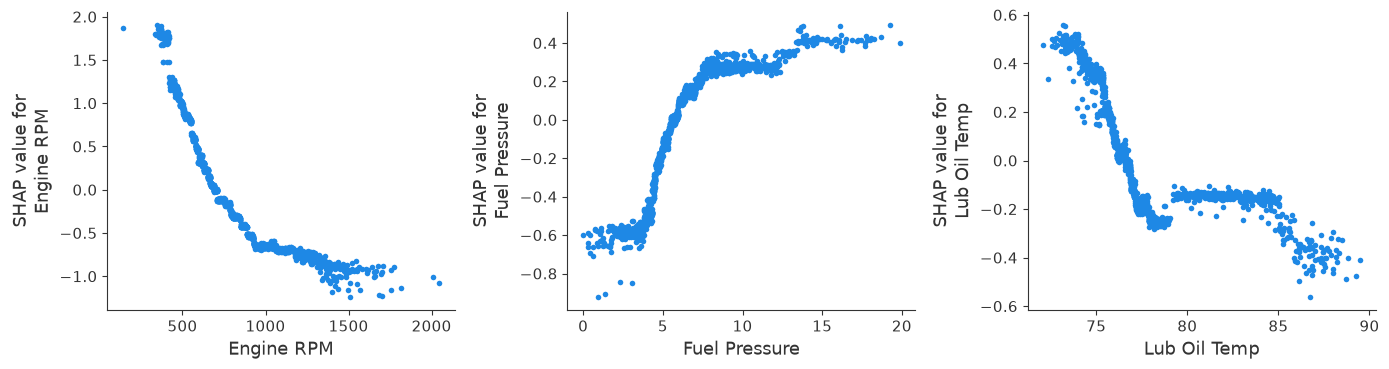

In [4]:
top3 = list(shap_imp.index[:3]); print('top 3 by mean |SHAP|:', top3)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, f in zip(axes, top3):
    shap.dependence_plot(f, sv, X_va, interaction_index=None, ax=ax, show=False)
plt.tight_layout(); plt.savefig(FIG / 'interp_shap_dependence_catboost.png', dpi=130); plt.show()

## 3. Partial dependence for the 3 most important sensors

Average predicted probability of "Needs Maintenance" as one sensor varies and the others keep their observed values (validation data).

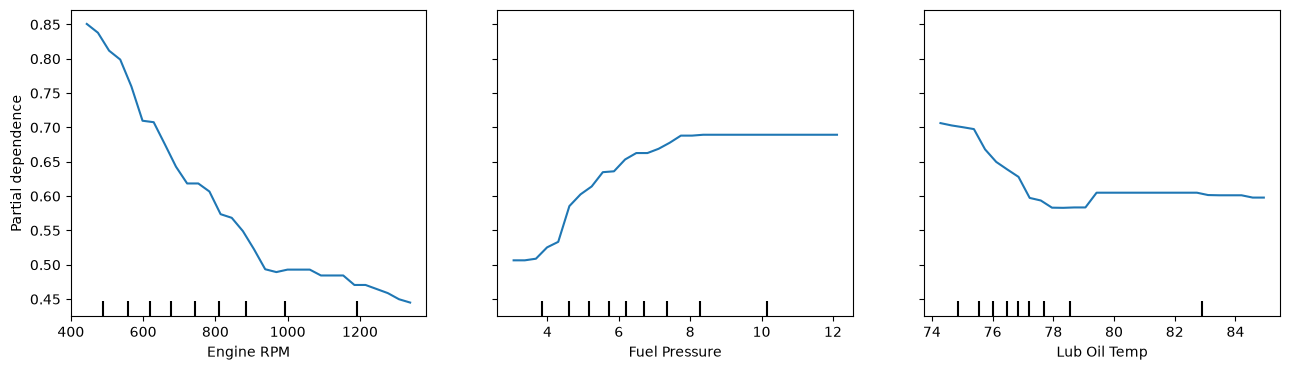

In [5]:
fig, ax = plt.subplots(figsize=(13, 3.8))
PartialDependenceDisplay.from_estimator(models['CatBoost'], X_va.astype(float), top3, kind='average', ax=ax, grid_resolution=30)
plt.tight_layout(); plt.savefig(FIG / 'interp_partial_dependence_catboost.png', dpi=130); plt.show()

## 4. Do the boosting libraries agree?

Permutation importance (validation AUC drop) for CatBoost, XGBoost and LightGBM, each with its own tuned parameters, plus rank agreement.

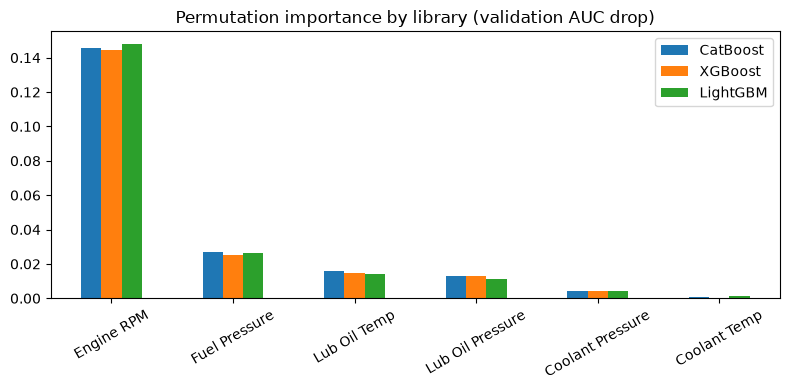

rank of each sensor (1 = most important):
                  CatBoost  XGBoost  LightGBM
Engine RPM               1        1         1
Fuel Pressure            2        2         2
Lub Oil Temp             3        3         3
Lub Oil Pressure         4        4         4
Coolant Pressure         5        5         5
Coolant Temp             6        6         6

Spearman rank correlation:
          CatBoost  XGBoost  LightGBM
CatBoost       1.0      1.0       1.0
XGBoost        1.0      1.0       1.0
LightGBM       1.0      1.0       1.0


In [6]:
cmp = pd.DataFrame({k: v['mean'] for k, v in perm.items()}).loc[shap_imp.index]
cmp.plot.bar(figsize=(8, 4), rot=30, title='Permutation importance by library (validation AUC drop)')
plt.tight_layout(); plt.savefig(FIG / 'interp_library_agreement.png', dpi=130); plt.show()
ranks = cmp.rank(ascending=False)
rho = pd.DataFrame({a: {b: spearmanr(cmp[a], cmp[b])[0] for b in cmp} for a in cmp}).round(2)
print('rank of each sensor (1 = most important):'); print(ranks.astype(int)); print('\nSpearman rank correlation:'); print(rho)

## Conclusion (plain English)

**Engine RPM is by far the most important sensor.** Shuffling it costs the model 0.146 AUC on validation, more than five times any other sensor (fuel pressure 0.027, lub oil temperature 0.016, lub oil pressure 0.013, coolant pressure 0.004, coolant temperature about 0). SHAP gives the same order. The effect is monotone: engines running at low RPM are flagged "Needs Maintenance" far more often (average predicted probability about 0.85 near 450 RPM, falling to about 0.45 above 1,100 RPM). Higher fuel pressure raises the predicted risk up to roughly 8 and then flattens. Cooler lub oil (below about 78) raises it, and the oil temperature effect is flat above that. SHAP also shows higher lub oil pressure pushing toward maintenance and higher coolant pressure pushing away from it, with small effects. Coolant temperature contributes almost nothing.

**The three boosting libraries agree completely:** CatBoost, XGBoost and LightGBM, each with its own tuned parameters, give the identical ranking of all six sensors (Spearman rank correlation 1.0). So the importance ranking reflects the data, not one library's quirks.

Limits: validation AUC is only about 0.71, so these are patterns the models lean on, not proven causes, and importance is measured on one 1,954-row split (the permutation error bars show the top three are clearly separated from the bottom two, but fuel pressure vs oil temperature vs oil pressure are close).